In [ ]:
!pip install pandas
!pip install metpy

In [265]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import metpy.calc as mpcalc
from metpy.plots import add_metpy_logo, Hodograph, SkewT
from metpy.units import units

In [316]:
def transformation_adiabatique(P,P0,T0):
    P0 = 1000
    landa=1.4
    return T0*(P/P0)**(1-landa)/landa

In [317]:
transformation_adiabatique(900,1000,10)

7.450320582218804

In [201]:
def rapoert_de_melange(P,T):#P en hPa et T par
    e0 = 6.11*units('hPa')
    Lv = 2.5*10**6*units('J/kg')
    Rv = 461*units('J/kg')
    T = T.to('K')
    Ts = T.magnitude
    ew = e0*np.exp(Lv/Rv*(1/273 - 1/Ts)) # la valeur de T est en Kelvien mais n'esp unites
    return 0.622*(ew/(P-ew))

In [203]:
rapoert_de_melange(1000*units('hPa'),17*units('degC')).to('g/kg')

12.543622881403955 <Unit('gram / kilogram')>

In [217]:
def f(P,T):
    Te = 273*units('K') # units est K
    Lv = 2.5*10**6*units('J/kg') # J/kg
    Cp = 1005*units('J/(K*kg)') # J/kgK
    Ma = 28.96*10**-3*units('kg/mol') # Kg/mol
    Mv = 18*10**-3*units('kg/mol') # kg/mol
    R = 8.314*units('J/(K*mol)') # J/K*mol
    Ra = R/Ma
    r = rapoert_de_melange(P*units('hPa'),T) 
    Tv = T*(1+1.608*r)/(1+r)
    Cph = Cp*(1+1.88*r)/(1+r)
    return (Tv**2)*((Ra + Lv*r/Tv)/(Cph + Lv**2*r*Mv/(R*T**2)))/(P*Te)

def transformation_pseudo_adiabatique(P,P0,T0,n=10):
    presion = np.linspace(P0,P,n)
    
    delta = presion[1]-presion[0]
    Temprature = [0]*n
    Temprature[0] = T0.to('K')
    for i in range(1,n):
        Temprature[i]= Temprature[i-1] + delta*f(presion[i-1],Temprature[i-1])
    return Temprature
    

In [220]:
transformation_pseudo_adiabatique(700,1000,10*units('degC'),100)[-1].to('degC')

-7.030085011493043 <Unit('degree_Celsius')>

In [95]:
cols = ['PRES' ,'HGHT' ,'TEMP','DWPT','FRPT','RELH','RELI','MIXR','DRCT','SKNT','THTA','THTE','THTV']
df = pd.read_csv('../data/raw/71043_norman-wells_2024-01-01_00Z.txt',names=cols,sep='\s+',skiprows=1)
df.head()

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_40590/3138629677.py:2: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('data.txt',names=cols,sep='\s+',skiprows=1)


,PRES,HGHT,TEMP,DWPT,FRPT,RELH,RELI,MIXR,DRCT,SKNT,THTA,THTE,THTV
0,1009.0,94,-14.1,-18.0,-16.1,72,83,0.92,310.0,8.0,258.4,261.0,258.5
1,1000.0,161,-14.7,-18.6,-16.6,72,84,0.89,315.0,15.0,258.4,260.9,258.6
2,981.0,305,-15.9,-18.9,-16.9,78,91,0.88,305.0,24.0,258.6,261.1,258.8
3,941.9,610,-18.6,-19.6,-17.6,91,110,0.86,300.0,40.0,259.0,261.4,259.1
4,931.0,697,-19.3,-19.8,-17.8,96,116,0.86,306.0,38.0,259.1,261.5,259.2


In [252]:
p = df['PRES'].values * units.hPa
p = p[p.magnitude>80]
T = df['TEMP'].values * units.degC
T = T[0:len(p)]
Td = df['DWPT'].values * units.degC
Td = Td[0:len(p)]
THTA = df['THTA'].values*units.K
THTA = THTA[0:len(p)]

In [273]:
def det_thtaw(p,T,Td):
    THTAw = [0]*len(p)
    for i in range(len(THTAw)):
        lcl_pressure, lcl_temperature = mpcalc.lcl(p[i], T[i], Td[i])
        THTAw[i] = transformation_pseudo_adiabatique(1000,lcl_pressure.magnitude,lcl_temperature,n=10)[-1].to('degC')
    return THTAw
def det_tw(p,T,Td):
    THTAw = [0]*len(p)
    for i in range(len(THTAw)):
        lcl_pressure, lcl_temperature = mpcalc.lcl(p[i], T[i], Td[i])
        THTAw[i] = transformation_pseudo_adiabatique(p[i].magnitude,lcl_pressure.magnitude,lcl_temperature,n=10)[-1].magnitude
    return THTAw

In [280]:
THTAw = det_thtaw(p,T,Td)
Tw = det_tw(p,T,Td)*units.K
len(Tw)==len(p)

True

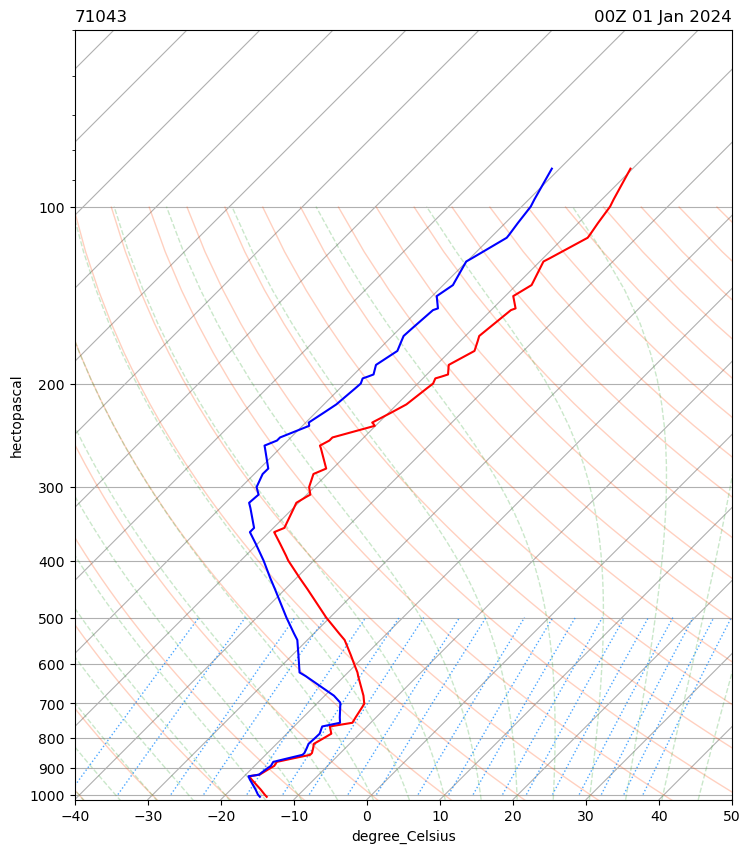

In [318]:
fig = plt.figure(figsize=(10, 10))
skew = SkewT(fig, rotation=45)
skew.plot(p, T, 'r')
skew.plot(p, Tw, 'b')
# Add the relevant special lines
pressure = np.arange(1000, 499, -100) * units('hPa')
mixing_ratio = np.array([0.1, 0.2, 0.4, 0.6, 1, 1.5, 2, 3, 4,
                        6, 8, 10, 13, 16, 20, 25, 30, 36, 42]).reshape(-1, 1) * units('g/kg')
skew.plot_dry_adiabats(t0=np.arange(233, 533, 10) * units.K, alpha=0.25,linestyles='-',
                       colors='orangered', linewidths=1)
skew.plot_moist_adiabats(t0=np.arange(233, 400, 5) * units.K, alpha=0.25,linestyles='--',
                         colors='tab:green', linewidths=1)
skew.plot_mixing_lines(pressure=pressure, mixing_ratio=mixing_ratio,linestyles='dotted',
                       colors='dodgerblue', linewidths=1)
#dim
skew.ax.set_ylim(1020, 50)
skew.ax.set_xlim(-40, 50)

# Add some titles
plt.title('71043', loc='left')
plt.title('00Z 01 Jan 2024', loc='right')
plt.savefig('../results/figures/skewt_norman-wells.png')
plt.show()

In [293]:
def Convective_Selective(Pc,Tc,dfpresion,dftemprateur):
    P = dfpresion[dfpresion.magnitude>Pc]
    for i in range(len(P)):
        valeus_pseudo_adiabaique = transformation_pseudo_adiabatique(P[i].magnitude,Pc,Tc,n=100)[-1]
        if valeus_pseudo_adiabaique < T[i+len(dfpresion)-len(P)]:
            pass
        else:
            return True
    return False

In [294]:
stability =  {}
for i in range(len(THTA)-1):
  if THTA[i] < THTA[i+1]:
    if THTAw[i] < THTAw[i+1]:
      stability[(p[i],p[i+1])] = 'Stabilité absolue'
    else:
        Pc, Tc =  mpcalc.lcl(p[i],T[i],Td[i])
        if Convective_Selective(Pc.magnitude,Tc,p[i+1:],T[i+1:]) == True:
            stability[(p[i],p[i+1])] = 'Instabilite Convective Selective'
        else:
            stability[(p[i],p[i+1])] = 'Instabilite Convective Latente'
  else:
    if THTAw[i] < THTAw[i+1]:
      stability[(p[i],p[i+1])] = 'Instabilité sèche'
    else:
      stability[(p[i],p[i+1])] = 'Instabilité absolue'

In [295]:
L = list(stability.keys())
new_version_stability = {}
i=0
while i<len(L)-1 :
  j=0
  while i+1+j<len(L) and  stability[L[i+j]] == stability[L[i+1+j]]:
    j += 1
  new_version_stability[(p[i],p[i+1+j])] = stability[L[i]]
  i += j+1

In [296]:
new_version_stability

{(1009.0 <Unit('hectopascal')>,
  1000.0 <Unit('hectopascal')>): 'Instabilité absolue',
 (1000.0 <Unit('hectopascal')>,
  697.0 <Unit('hectopascal')>): 'Stabilité absolue',
 (697.0 <Unit('hectopascal')>,
  620.0 <Unit('hectopascal')>): 'Instabilite Convective Selective',
 (620.0 <Unit('hectopascal')>,
  234.4 <Unit('hectopascal')>): 'Stabilité absolue',
 (234.4 <Unit('hectopascal')>,
  233.0 <Unit('hectopascal')>): 'Instabilité sèche',
 (233.0 <Unit('hectopascal')>,
  86.2 <Unit('hectopascal')>): 'Stabilité absolue'}

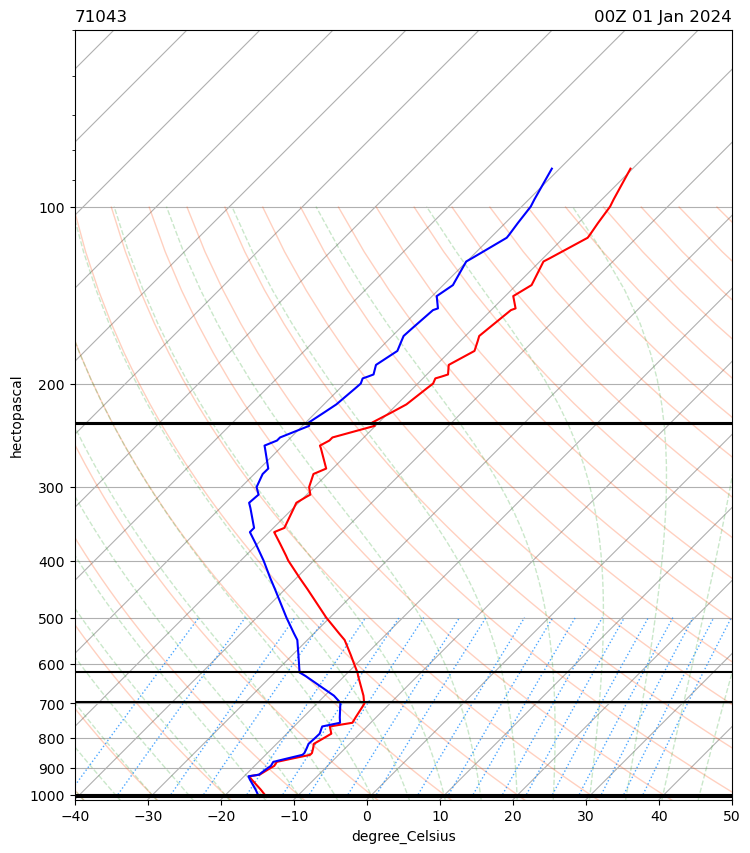

In [299]:
fig = plt.figure(figsize=(10, 10))
skew = SkewT(fig, rotation=45)
skew.plot(p, T, 'r')
skew.plot(p, Tw, 'b')
# Add the relevant special lines
pressure = np.arange(1000, 499, -100) * units('hPa')
mixing_ratio = np.array([0.1, 0.2, 0.4, 0.6, 1, 1.5, 2, 3, 4,
                        6, 8, 10, 13, 16, 20, 25, 30, 36, 42]).reshape(-1, 1) * units('g/kg')
skew.plot_dry_adiabats(t0=np.arange(233, 533, 10) * units.K, alpha=0.25,linestyles='-',
                       colors='orangered', linewidths=1)
skew.plot_moist_adiabats(t0=np.arange(233, 400, 5) * units.K, alpha=0.25,linestyles='--',
                         colors='tab:green', linewidths=1)
skew.plot_mixing_lines(pressure=pressure, mixing_ratio=mixing_ratio,linestyles='dotted',
                       colors='dodgerblue', linewidths=1)
#add stability
x = [-200,-10,0,50,80]
for values in list(new_version_stability.keys()) :
  plt.plot(x,[values[0].magnitude]*5, color='black')
skew.ax.set_ylim(1020, 50)
skew.ax.set_xlim(-40, 50)

# Add some titles
plt.title('71043', loc='left')
plt.title('00Z 01 Jan 2024', loc='right')
plt.show()

In [311]:
# resulta finale
def satbility(p):
  for intervale in list(new_version_stability.keys()):
    if p<=intervale[0] and p>intervale[1]:
      return new_version_stability[intervale]

In [314]:
satbility(800*units('hPa'))

'Stabilité absolue'